# CardioIA · CNN e Transfer Learning
As duas abordagens são avaliadas nos mesmos exames reservados. A seleção da época usa Average Precision na validação, e o limiar maximiza o F1 positivo nesse mesmo conjunto.

In [1]:
from pathlib import Path
import subprocess
import sys

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fase4/src").is_dir()), None)
if raiz is None:
    raiz = Path.cwd() / "cardioia"
    if not (raiz / "fase4/src").is_dir():
        subprocess.run(["git", "clone", "--branch", "fase4", "--depth", "1",
                        "https://github.com/marcus-vlgarcia/cardioia.git", str(raiz)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(raiz / "fase4/requirements.txt")], check=True)
sys.path.insert(0, str(raiz / "fase4/src"))


In [2]:
import inspect
from modelos import cnn_simples, extrator_resnet, classificador_resnet
from treinar import executar, ajustar
print(inspect.getsource(cnn_simples))
print(inspect.getsource(extrator_resnet))
print(inspect.getsource(classificador_resnet))

def cnn_simples():
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Dropout(0.25), nn.Linear(64 * 7 * 7, 1),
    )

def extrator_resnet():
    pesos = ResNet18_Weights.IMAGENET1K_V1
    destino = Path(torch.hub.get_dir()) / "checkpoints" / Path(pesos.url).name
    baixar_verificado(pesos.url, destino, "sha256",
                      "f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec")
    rede = resnet18(weights=pesos)
    rede.fc = nn.Identity()
    return rede.requires_grad_(False).eval()

def classificador_resnet():
    return nn.Linear(512, 1)



In [3]:
print(inspect.getsource(ajustar))

def ajustar(modelo, loaders, device, taxa):
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=taxa)
    perda = nn.BCEWithLogitsLoss()
    melhor, estado, historico = -1, None, []
    for epoca in range(EPOCAS):
        modelo.train()
        total = 0.0
        for x, y in loaders["train"]:
            otimizador.zero_grad()
            erro = perda(modelo(x.to(device)).flatten(), y.to(device, dtype=torch.float32))
            erro.backward()
            otimizador.step()
            total += erro.item() * len(y)
        scores, y = avaliar_escores(modelo, loaders["val"], device)
        ap = float(average_precision_score(y, scores))
        historico.append({"epoca": epoca + 1, "loss_treino": total / len(loaders["train"].dataset),
                          "ap_validacao": ap})
        print(f"Época {epoca + 1:02d} | AP validação {ap:.4f}", flush=True)
        if ap > melhor:
            melhor, estado = ap, copy.deepcopy(modelo.state_dict())
    modelo.load_state_dict(estado

In [4]:
import json
from dados import RESULTADOS
REPETIR_TREINO = False
resultado = executar() if REPETIR_TREINO else json.loads((RESULTADOS / "metricas.json").read_text())

In [5]:
import pandas as pd
linhas = []
for nome, m in resultado["modelos"].items():
    for classe, descricao in [("0", "Sem rótulo"), ("1", "Com rótulo")]:
        c = m["relatorio"][classe]
        linhas.append({"Modelo": nome, "Classe": descricao, "Acurácia": m["acuracia"],
                       "Precisão": c["precision"], "Recall": c["recall"], "F1": c["f1-score"],
                       "Amostras": c["support"], "AP": m["average_precision"], "Limiar": m["limiar"]})
display(pd.DataFrame(linhas).round(3))

,Modelo,Classe,Acurácia,Precisão,Recall,F1,Amostras,AP,Limiar
0,cnn,Sem rótulo,0.953,0.983,0.969,0.976,7808.0,0.167,0.641
1,cnn,Com rótulo,0.953,0.191,0.305,0.235,190.0,0.167,0.641
2,resnet18,Sem rótulo,0.933,0.978,0.952,0.965,7808.0,0.054,0.539
3,resnet18,Com rótulo,0.933,0.065,0.137,0.089,190.0,0.054,0.539


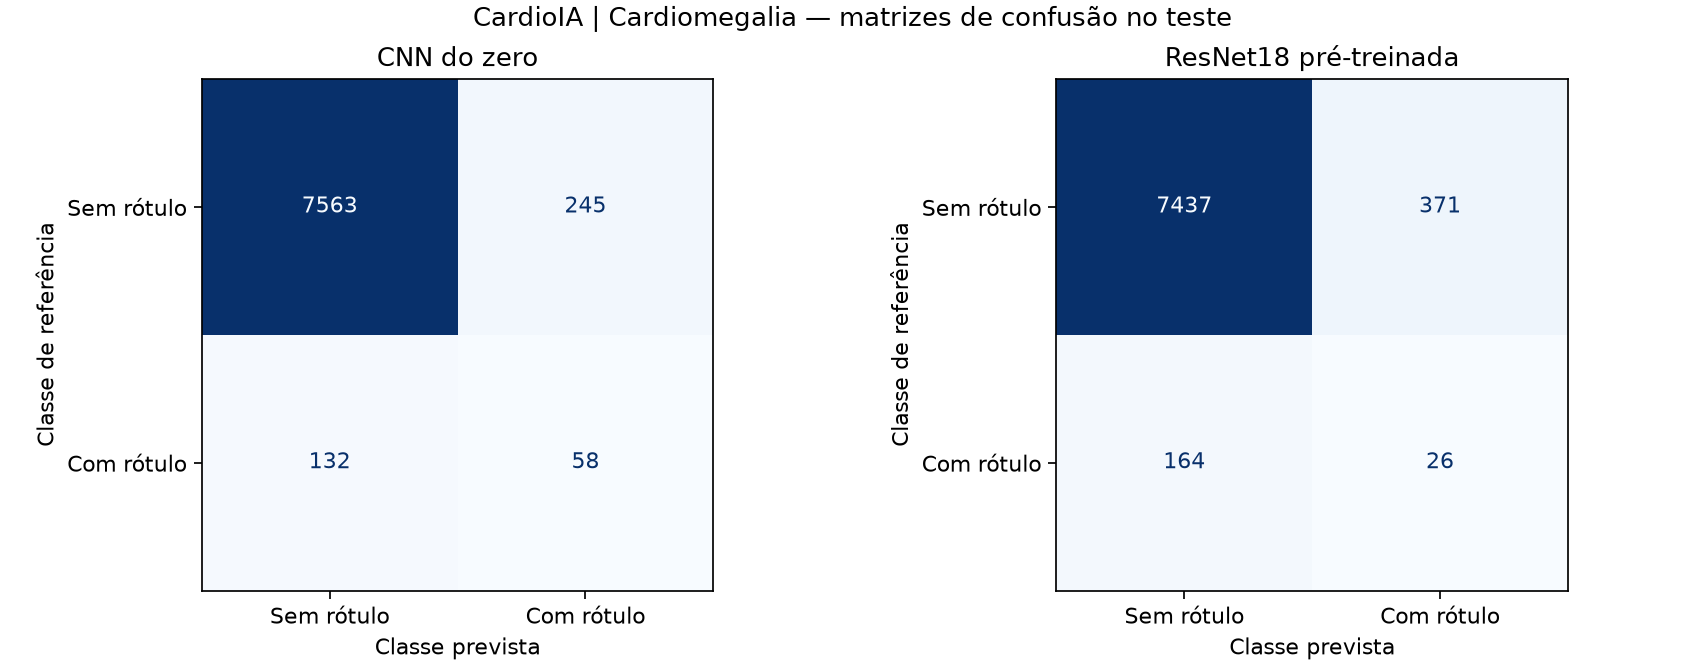

In [6]:
from IPython.display import Image, display
display(Image(filename=str(RESULTADOS / "matrizes_confusao.png")))

A acurácia deve ser lida junto com a matriz de confusão e o F1 da classe positiva. O teste contém muitos exames sem o rótulo, então acertar a classe majoritária pode produzir acurácia alta mesmo quando a identificação dos positivos é ruim.